# Caribbean farmer safety reanalysis

## Findings

The original latent SEM remains inadequately supported. Main results are exploratory associations between transparent observed scores. Chemical handling is inversely associated with recent pesticide symptom recurrence; community norms, training and safety confidence are associated with PPE use. Cross-sectional data cannot determine intervention efficacy or causal mediation.

## Context and methods

2,000 farmers, January–March 2026; WVU exemption 2401909110. The public dataset omits original survey identifiers and geographic labels and uses shuffled release rows. Two E15 omissions are corrected and four invalid A11 values set missing. Nominal and ordinal demographic controls enter as categorical factors. Primary linear associations use HC3 covariance estimates, t confidence intervals, and Holm adjustment across 28 focal tests. Main pesticide models include current users. Full specifications and limits are in analysis_specification.txt and README.md.

In [1]:
from pathlib import Path
import os, subprocess, pandas as pd
from IPython.display import display, Image
root=Path.cwd()
assert (root/'data/survey_numeric_clean.csv').exists()
RUN_MODELS=False  # Set True to rerun the included R scripts after installing dependencies.
if RUN_MODELS:
    for script in ['code/01_observed_associations.R','code/02_sem_diagnostics.R']:
        completed=subprocess.run(['Rscript',script],check=True,capture_output=True,text=True)
        print(script, 'completed')
else:
    print('Displaying results from the executed R scripts supplied with this release.')

Displaying results from the executed R scripts supplied with this release.


## Data checks

The release contains 2,000 rows and 1,000 participants per country. No respondent was removed from primary analyses solely because an answer profile matched another respondent. Missing scores require complete constituent items. Work-limitation percentages exclude follow-up responses when the parent pain item was negative.

In [2]:
data=pd.read_csv('data/survey_numeric_clean.csv')
assert len(data)==2000 and data.record_id.is_unique
assert not {'Survey ID','Location'}.intersection(data.columns)
assert data.A11.dropna().isin([0,1]).all()
display(data.groupby('Country').size().rename('Participants').to_frame())
display(pd.read_csv('data/corrections.csv'))

,Participants
Country,
1,1000
2,1000


,record_id,item,original,cleaned,reason
0,175,A11,2,missing,Response outside binary questionnaire options;...
1,216,E15,missing,3,Valid highest distress category in labelled so...
2,641,A11,2,missing,Response outside binary questionnaire options;...
3,1278,A11,2,missing,Response outside binary questionnaire options;...
4,1370,E15,missing,3,Valid highest distress category in labelled so...
5,1421,A11,2,missing,Response outside binary questionnaire options;...


## Measurement and SEM diagnostics

Both conventional scaled and corrected robust categorical fit indices are retained. A favorable scaled CFI does not establish measurement adequacy when robust fit is poor. The grouped content model has a non-positive-definite Trinidad and Tobago polychoric matrix, so corrected robust fit is unavailable. Latent country pathway comparisons are therefore not interpreted.

In [3]:
rows=[]
for name in ['original_ordinal_pooled','original_ordinal_groups','content_ordinal_pooled','content_ordinal_groups']:
    fit=pd.read_csv(Path('results/sem')/(name+'_fit.csv')).set_index('metric').value
    rows.append({'Model':name,'CFI scaled':fit.get('cfi.scaled'),'CFI robust':fit.get('cfi.robust'),'RMSEA scaled':fit.get('rmsea.scaled'),'RMSEA robust':fit.get('rmsea.robust'),'SRMR':fit.get('srmr')})
shown=pd.DataFrame(rows).round(3).astype(object)
display(shown.where(shown.notna(),'Unavailable'))

,Model,CFI scaled,CFI robust,RMSEA scaled,RMSEA robust,SRMR
0,original_ordinal_pooled,0.964,0.809,0.062,0.103,0.065
1,original_ordinal_groups,0.961,0.733,0.072,0.128,0.081
2,content_ordinal_pooled,0.957,0.836,0.053,0.082,0.057
3,content_ordinal_groups,0.951,Unavailable,0.062,Unavailable,0.072


## Exploratory associations

Coefficients represent outcome-score units per one predictor-score unit. Intervals are nominal 95% HC3 and do not account for unidentified community clustering. Filled markers indicate Holm-adjusted p < .05; open markers do not. These coefficients are not standardized latent path coefficients.

,outcome,term,estimate,lower,upper,p_holm,n
0,Training,Support,0.0669,0.0332,0.1007,0.002,1961
1,Training,Oversight,0.2372,0.2069,0.2674,<0.001,1961
2,PPE,Support,-0.0289,-0.0747,0.0170,1.000,1835
3,PPE,Oversight,-0.0060,-0.0431,0.0310,1.000,1835
4,PPE,Training,0.2305,0.1774,0.2836,<0.001,1835
5,PPE,Risk,-0.0086,-0.0895,0.0722,1.000,1835
6,PPE,Barriers,-0.1542,-0.2040,-0.1044,<0.001,1835
7,PPE,Benefits,0.0372,-0.0386,0.1131,1.000,1835
8,PPE,Coping,0.0574,-0.0218,0.1366,1.000,1835
9,PPE,Confidence,0.2552,0.1733,0.3372,<0.001,1835


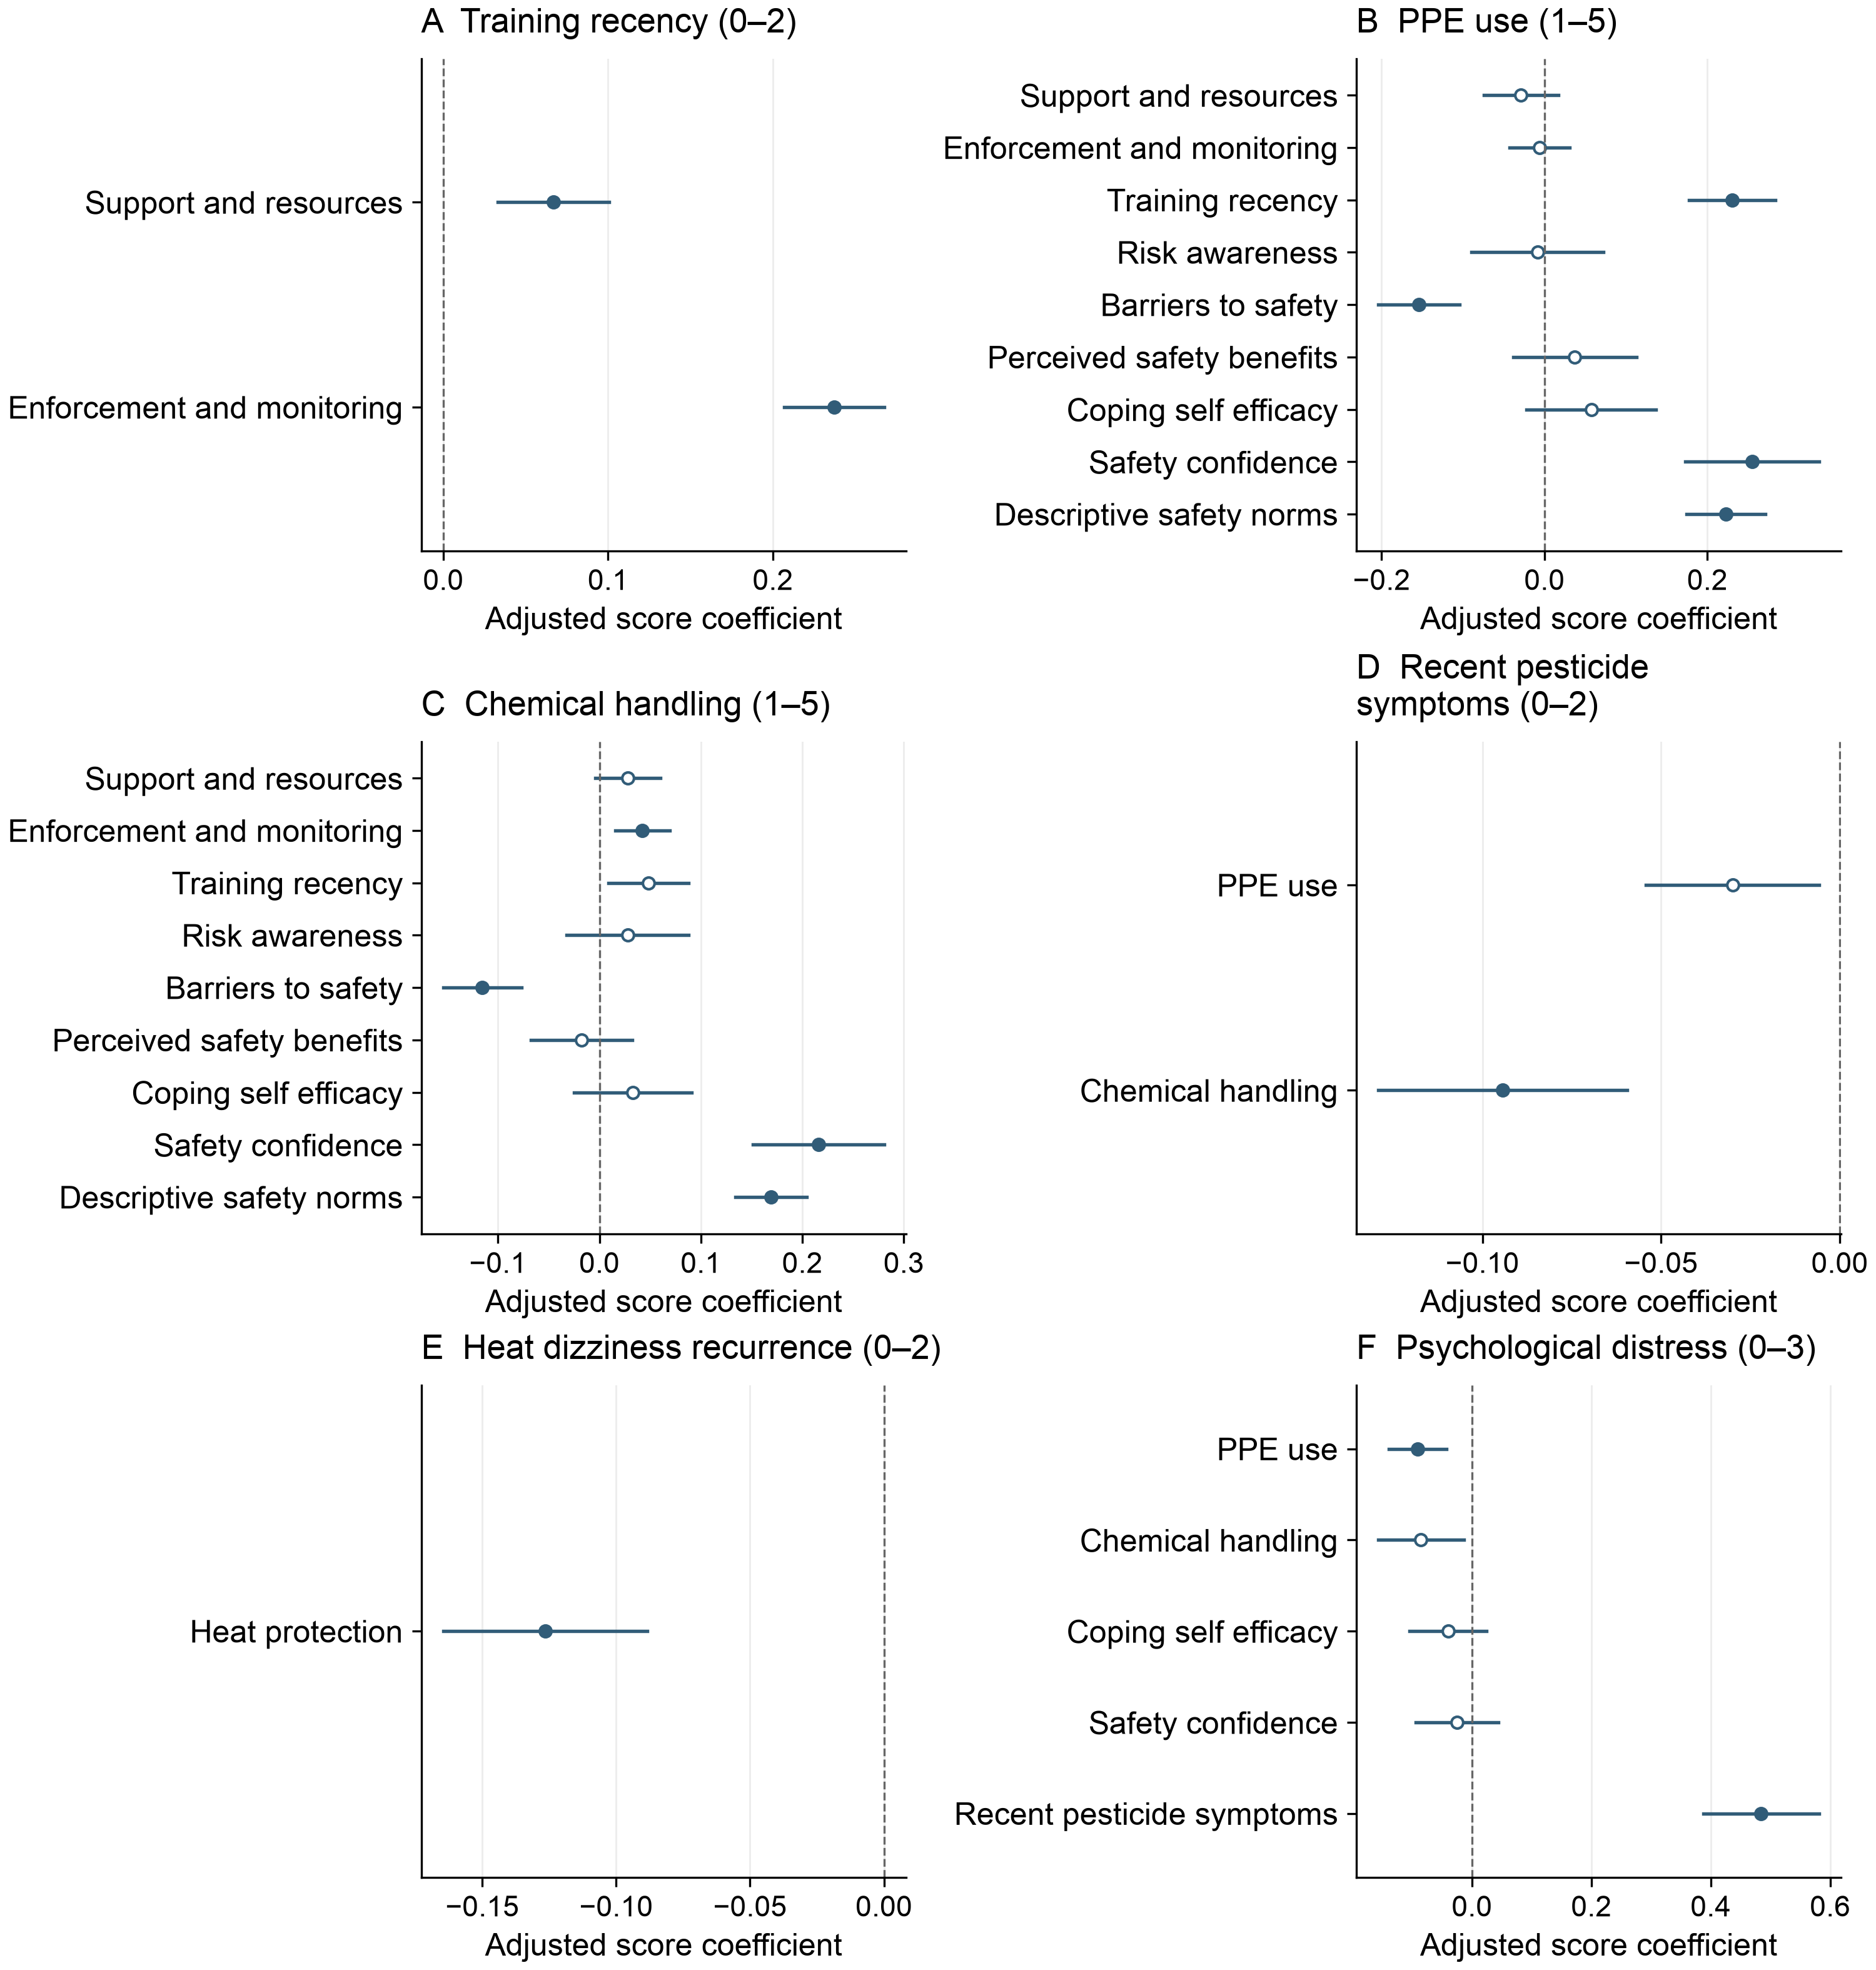

In [4]:
results=pd.read_csv('results/observed/main_focal.csv')
assert len(results)==28
shown=results[['outcome','term','estimate','lower','upper','p_holm','n']].copy()
shown['p_holm']=shown.p_holm.map(lambda p: '<0.001' if p<0.001 else f'{p:.3f}')
display(shown.round(4))
display(Image(filename='figures/Fig1.png',width=1000))

## Sensitivity analyses

All-farmer, joint-complete-case and unique-profile analyses retain the direction of primary focal associations. Country-stratified estimates are descriptive, with no claim that differences in significance demonstrate country effects. Binary symptom/heat outcomes test different endpoints and use unadjusted exploratory p values.

In [5]:
all_results=pd.read_csv('results/observed/all_coefficients.csv')
subset=all_results[(all_results.focal)&(all_results.term.isin(['Norms','Training','Handling','HeatProtection','Symptoms']))]
display(subset[['analysis','outcome','term','estimate','lower','upper','n']].round(4).reset_index(drop=True))

,analysis,outcome,term,estimate,lower,upper,n
0,main,PPE,Training,0.2305,0.1774,0.2836,1835
1,main,PPE,Norms,0.2227,0.1744,0.2711,1835
2,joint_complete,PPE,Training,0.2320,0.1785,0.2856,1817
3,joint_complete,PPE,Norms,0.2210,0.1726,0.2695,1817
4,unique_profiles,PPE,Training,0.2318,0.1786,0.2851,1814
5,unique_profiles,PPE,Norms,0.2200,0.1712,0.2689,1814
6,all_farmers,PPE,Training,0.2405,0.1840,0.2969,1922
7,all_farmers,PPE,Norms,0.2273,0.1760,0.2787,1922
8,country_1,PPE,Training,0.1126,0.0397,0.1855,880
9,country_1,PPE,Norms,0.2409,0.1664,0.3153,880


## Interpretation

This reanalysis does not validate the original SEM. It supports narrower observational findings and identifies targets for future prospective and intervention studies. Survey design, self report, missing cluster metadata, adapted distress items, response duplication and nonapplicability for some nonusers limit inference. See complete numerical outputs, source hashes, correction log and code. Before journal submission, authors should document any original sample-size rationale, review identical response profiles against source records, approve the revised text, and finalize verified archive links. Active-farmer eligibility and agreement by all approached farmers have been confirmed.